# _**Project of Comp9444**_
**_Named Entity Recognition (NER) for Biomedical Texts using Large Language Models (LLMs)_**

这里需要写一下整个项目的结构（目录）：this notebook contain ......

## **_1. Introduction and Library Imports_**

这里需要说明问题的定义，包括研究的背景和动机，以及需要解决的问题

最后单独介绍一下引用的库（可以不做）


In [1]:
# import all the libs here
import numpy as np
import pandas as pd
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
import shutil

print('all the libs are successfully imported')

all the libs are successfully imported


## **_2. Data Loading_**

这里需要说明数据来源，然后解释一下因为数据源下载格式是zip 文件，没办法直接下载到内存里进行操作，只能借助外部文件夹

还需要介绍一下，数据是三个txt文件，数据源已经分好了训练测试和验证

这个目前只适用于windows版本，MAC/Linux可能有问题

In [2]:
# from one of its subdirectories.
notebook_name = "MedNLP_research.ipynb"
notebook_dir = next(
    (directory for directory in (Path.cwd(), *Path.cwd().parents)
     if (directory / notebook_name).is_file()),
    Path.cwd(),
)
raw_data_dir = notebook_dir / "Dataset" / "RawData"
raw_data_dir.mkdir(parents=True, exist_ok=True)

# download for data scource
datasets = {
    "training": {
        "url": "https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/NCBItrainset_corpus.zip",
        "source_name": "NCBItrainset_corpus.txt",
        "target_name": "NCBI_training.txt",
    },
    "validation": {
        "url": "https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/NCBIdevelopset_corpus.zip",
        "source_name": "NCBIdevelopset_corpus.txt",
        "target_name": "NCBI_validation.txt",
    },
    "testing": {
        "url": "https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/NCBItestset_corpus.zip",
        "source_name": "NCBItestset_corpus.txt",
        "target_name": "NCBI_testing.txt",
    },
}

for split, dataset_info in datasets.items():
    target_path = raw_data_dir / dataset_info["target_name"]

    if target_path.is_file():
        print(f"{split.capitalize()} set already exists: {target_path}")
        continue

    archive_path = raw_data_dir / Path(dataset_info["url"]).name
    partial_archive_path = archive_path.with_suffix(archive_path.suffix + ".part")
    partial_target_path = target_path.with_suffix(target_path.suffix + ".part")

    print(f"Downloading {split} set...")
    urlretrieve(dataset_info["url"], partial_archive_path)
    partial_archive_path.replace(archive_path)

    # decompress the file
    try:
        with ZipFile(archive_path) as zip_file:
            source_member = next(
                member for member in zip_file.namelist()
                if Path(member).name == dataset_info["source_name"]
            )
            with zip_file.open(source_member) as source, partial_target_path.open("wb") as target:
                shutil.copyfileobj(source, target)
        partial_target_path.replace(target_path)
    finally:
        archive_path.unlink(missing_ok=True)
        partial_target_path.unlink(missing_ok=True)

    print(f"Saved {split} set to: {target_path}")

print("NCBI Disease Corpus download and extraction completed.")

Training set already exists: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\RawData\NCBI_training.txt
Validation set already exists: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\RawData\NCBI_validation.txt
Testing set already exists: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\RawData\NCBI_testing.txt
NCBI Disease Corpus download and extraction completed.


## **_3. Data Processing and Analysis_**

这里要说明处理的流程：

### 3.0 基础处理


In [9]:
import json
from pathlib import Path

# Locate the dataset directories from the project root.
project_dir = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "Dataset" / "RawData").is_dir()),
    Path.cwd(),
)
raw_data_dir = project_dir / "Dataset" / "RawData"
processed_data_dir = project_dir / "Dataset" / "ProcessedData"
processed_data_dir.mkdir(parents=True, exist_ok=True)

source_files = (
    "NCBI_training.txt",
    "NCBI_validation.txt",
    "NCBI_testing.txt",
)


def convert_pubtator_to_jsonl(input_path, output_path):
    # Keep every source block, including repeated PMIDs.
    documents = []
    document = None

    with input_path.open(encoding="utf-8") as source:
        for raw_line in source:
            line = raw_line.rstrip("\r\n")
            if not line:
                if document is not None:
                    documents.append(document)
                    document = None
                continue

            if "|t|" in line or "|a|" in line:
                pmid, section, content = line.split("|", 2)
                if section == "t":
                    document = {"pmid": pmid, "title": content, "abstract": "", "entities": []}
                else:
                    document["abstract"] = content
            else:
                fields = line.split("\t")
                if len(fields) < 5:
                    raise ValueError(f"Invalid annotation line: {line}")
                pmid, start, end, mention, entity_type = fields[:5]
                document["entities"].append(
                    {
                        "start": int(start),
                        "end": int(end),
                        "mention": mention,
                        "type": entity_type,
                    }
                )

    if document is not None:
        documents.append(document)

    mismatch_count = 0
    boundary_correction_count = 0
    with output_path.open("w", encoding="utf-8") as destination:
        for document_index, document in enumerate(documents):
            # Corpus offsets use: title + one space + abstract.
            text = document["title"] + " " + document["abstract"]
            entities = []

            for entity in document["entities"]:
                start, end = entity["start"], entity["end"]
                if not 0 <= start < end <= len(text):
                    raise ValueError(
                        f"Invalid offset in PMID {document['pmid']}: [{start}, {end})"
                    )
                if text[start:end] != entity["mention"]:
                    mismatch_count += 1

                # Repair corpus annotations that end inside a word. Such
                # partial-word spans cannot align with WordPiece boundaries.
                original_end = end
                while (
                    end < len(text)
                    and text[end - 1].isalnum()
                    and text[end].isalnum()
                ):
                    end += 1
                boundary_correction_count += int(end != original_end)
                entities.append(
                    {"start": start, "end": end, "type": entity["type"]}
                )

            record = {
                "record_id": f"{input_path.stem}-{document_index:04d}",
                "pmid": document["pmid"],
                "title": document["title"],
                "abstract": document["abstract"],
                "text": text,
                "entities": entities,
            }
            destination.write(json.dumps(record, ensure_ascii=False) + "\n")

    return len(documents), mismatch_count, boundary_correction_count


for source_name in source_files:
    input_path = raw_data_dir / source_name
    output_path = processed_data_dir / Path(source_name).with_suffix(".jsonl").name
    (
        document_count,
        mismatch_count,
        boundary_correction_count,
    ) = convert_pubtator_to_jsonl(input_path, output_path)
    print(
        f"Saved {document_count} documents to: {output_path} "
        f"({mismatch_count} annotation text mismatch(es), "
        f"{boundary_correction_count} boundary correction(s))"
    )

Saved 593 documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\ProcessedData\NCBI_training.jsonl (1 annotation text mismatch(es), 2 boundary correction(s))
Saved 100 documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\ProcessedData\NCBI_validation.jsonl (0 annotation text mismatch(es), 0 boundary correction(s))
Saved 100 documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\ProcessedData\NCBI_testing.jsonl (0 annotation text mismatch(es), 0 boundary correction(s))


数据完成基础清洗之后，接下来进行初步数据分析

### 3.1 数据规模与文档长度


,Documents,Unique PMIDs,Repeated Records,Entity Mentions,Unique Entity Texts,Mean Document Length,Median Document Length,95th Percentile Length,Maximum Document Length
Split,,,,,,,,,
Training,593,592,1,5145,1690,1264.72,1276.0,1909.8,2656
Validation,100,100,0,787,363,1326.40,1272.0,1895.4,2193


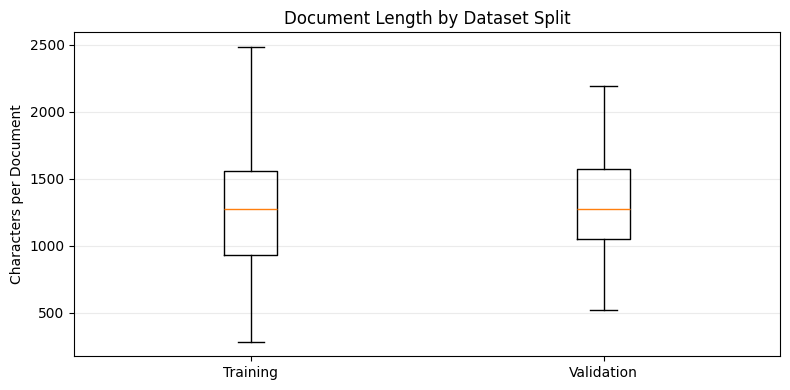

In [10]:
import matplotlib.pyplot as plt
from IPython.display import display

# Load only the training and validation splits for exploratory analysis.
# Keep the testing split untouched to avoid test-set-driven decisions.
split_files = {
    "Training": "NCBI_training.jsonl",
    "Validation": "NCBI_validation.jsonl",
}
records_by_split = {}

for split, file_name in split_files.items():
    file_path = processed_data_dir / file_name
    with file_path.open(encoding="utf-8") as source:
        records_by_split[split] = [json.loads(line) for line in source if line.strip()]

# Summarise dataset size and document character lengths.
scale_rows = []
for split, records in records_by_split.items():
    document_lengths = pd.Series([len(record["text"]) for record in records])
    entity_texts = [
        record["text"][entity["start"]:entity["end"]]
        for record in records
        for entity in record["entities"]
    ]
    unique_pmids = len({record["pmid"] for record in records})

    scale_rows.append({
        "Split": split,
        "Documents": len(records),
        "Unique PMIDs": unique_pmids,
        "Repeated Records": len(records) - unique_pmids,
        "Entity Mentions": len(entity_texts),
        "Unique Entity Texts": len(set(entity_texts)),
        "Mean Document Length": document_lengths.mean(),
        "Median Document Length": document_lengths.median(),
        "95th Percentile Length": document_lengths.quantile(0.95),
        "Maximum Document Length": document_lengths.max(),
    })

scale_summary = pd.DataFrame(scale_rows).set_index("Split")
display(scale_summary.round(2))

# Compare document-length distributions across splits.
plt.figure(figsize=(8, 4))
plt.boxplot(
    [[len(record["text"]) for record in records_by_split[split]] for split in split_files],
    tick_labels=list(split_files),
    showfliers=False,
)
plt.title("Document Length by Dataset Split")
plt.ylabel("Characters per Document")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### 3.2 实体分布

,Entities per Document,"Entities per 1,000 Characters",Zero-Entity Documents,Mean Entity Length,Median Entity Length,95th Percentile Entity Length,Maximum Entity Length,Single-Word Entities (%),Multi-Word Entities (%)
Split,,,,,,,,,
Training,8.68,6.86,0,15.19,14.0,37.0,80,46.69,53.31
Validation,7.87,5.93,0,15.74,15.0,37.0,74,42.69,57.31


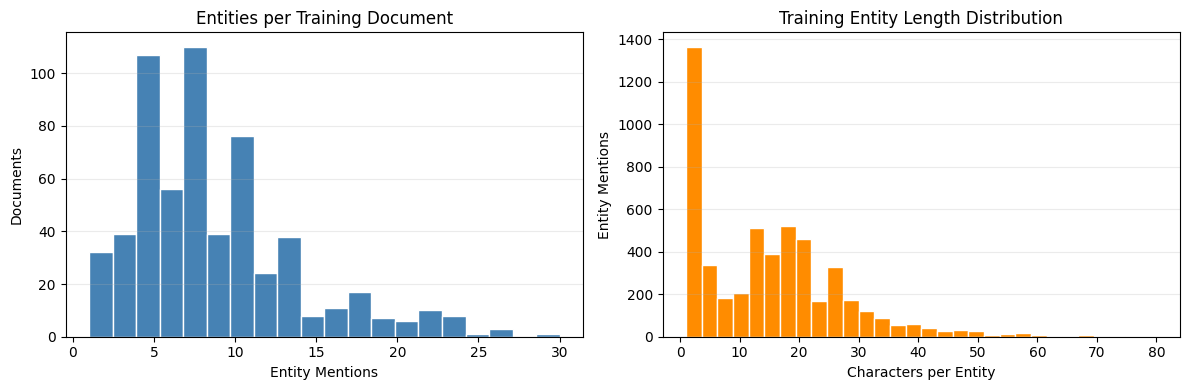

In [11]:
# Summarise entity density and character length for each split.
entity_rows = []
for split, records in records_by_split.items():
    entity_counts = pd.Series([len(record["entities"]) for record in records])
    entity_texts = [
        record["text"][entity["start"]:entity["end"]]
        for record in records
        for entity in record["entities"]
    ]
    entity_lengths = pd.Series([len(text) for text in entity_texts])
    total_characters = sum(len(record["text"]) for record in records)
    single_word_count = sum(len(text.split()) == 1 for text in entity_texts)

    entity_rows.append({
        "Split": split,
        "Entities per Document": entity_counts.mean(),
        "Entities per 1,000 Characters": len(entity_texts) / total_characters * 1000,
        "Zero-Entity Documents": int((entity_counts == 0).sum()),
        "Mean Entity Length": entity_lengths.mean(),
        "Median Entity Length": entity_lengths.median(),
        "95th Percentile Entity Length": entity_lengths.quantile(0.95),
        "Maximum Entity Length": entity_lengths.max(),
        "Single-Word Entities (%)": single_word_count / len(entity_texts) * 100,
        "Multi-Word Entities (%)": (len(entity_texts) - single_word_count) / len(entity_texts) * 100,
    })

entity_summary = pd.DataFrame(entity_rows).set_index("Split")
display(entity_summary.round(2))

# Plot the main entity distributions in the training set.
training_records = records_by_split["Training"]
training_entity_counts = [len(record["entities"]) for record in training_records]
training_entity_lengths = [
    entity["end"] - entity["start"]
    for record in training_records
    for entity in record["entities"]
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(training_entity_counts, bins=20, color="steelblue", edgecolor="white")
axes[0].set_title("Entities per Training Document")
axes[0].set_xlabel("Entity Mentions")
axes[0].set_ylabel("Documents")

axes[1].hist(training_entity_lengths, bins=30, color="darkorange", edgecolor="white")
axes[1].set_title("Training Entity Length Distribution")
axes[1].set_xlabel("Characters per Entity")
axes[1].set_ylabel("Entity Mentions")

for axis in axes:
    axis.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

Number of entity types: 4
Entity types: CompositeMention, DiseaseClass, Modifier, SpecificDisease


Split,Training,Validation,Total,Total (%)
Entity Type,,,,
SpecificDisease,2972,412,3384,57.05
Modifier,1289,214,1503,25.34
DiseaseClass,769,126,895,15.09
CompositeMention,115,35,150,2.53


Split,Training (%),Validation (%)
Entity Type,,
CompositeMention,2.24,4.45
DiseaseClass,14.95,16.01
Modifier,25.05,27.19
SpecificDisease,57.76,52.35


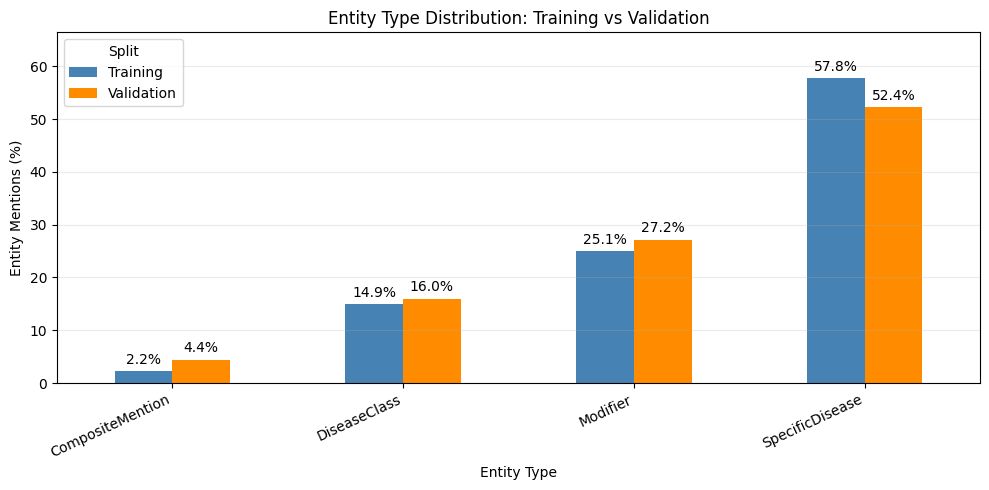

In [12]:
# Analyse entity mention types in the training and validation splits.
missing_type_records = [
    record["record_id"]
    for records in records_by_split.values()
    for record in records
    if any("type" not in entity for entity in record["entities"])
]
if missing_type_records:
    raise ValueError(
        "Entity type is missing from ProcessedData. "
        "Re-run Section 3.0 before this analysis."
    )

entity_types = sorted({
    entity["type"]
    for records in records_by_split.values()
    for record in records
    for entity in record["entities"]
})
print(f"Number of entity types: {len(entity_types)}")
print("Entity types:", ", ".join(entity_types))

type_distribution_rows = []
for split, records in records_by_split.items():
    split_types = [
        entity["type"]
        for record in records
        for entity in record["entities"]
    ]
    split_total = len(split_types)
    for entity_type in entity_types:
        count = split_types.count(entity_type)
        type_distribution_rows.append({
            "Split": split,
            "Entity Type": entity_type,
            "Count": count,
            "Percentage": count / split_total * 100,
        })

type_distribution = pd.DataFrame(type_distribution_rows)
type_count_summary = type_distribution.pivot(
    index="Entity Type", columns="Split", values="Count"
).reindex(columns=list(split_files)).astype(int)
type_count_summary["Total"] = type_count_summary.sum(axis=1)
type_count_summary["Total (%)"] = (
    type_count_summary["Total"]
    / type_count_summary["Total"].sum()
    * 100
)
display(type_count_summary.sort_values("Total", ascending=False).round(2))

type_percentage_summary = type_distribution.pivot(
    index="Entity Type", columns="Split", values="Percentage"
).reindex(columns=list(split_files))
display(type_percentage_summary.round(2).add_suffix(" (%)"))

# Compare within-split percentages so split size does not distort the chart.
plot_percentages = type_percentage_summary.loc[entity_types]
axis = plot_percentages.plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "darkorange"],
)
for container in axis.containers:
    axis.bar_label(container, fmt="%.1f%%", padding=3)
plt.title("Entity Type Distribution: Training vs Validation")
plt.xlabel("Entity Type")
plt.ylabel("Entity Mentions (%)")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, plot_percentages.to_numpy().max() * 1.15)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


### 3.3 tokenized by two methods
#### 3.3.1 BioBERT

In [14]:
from transformers.models.bert.tokenization_bert import BertTokenizerFast

BIOBERT_MODEL = "dmis-lab/biobert-base-cased-v1.1"
# BioBERT v1.1 inherits the BERT-base-cased WordPiece vocabulary.

BIOBERT_TOKENIZER = "google-bert/bert-base-cased"

ENTITY_TYPES = (
    "SpecificDisease",
    "DiseaseClass",
    "CompositeMention",
    "Modifier",
)
BIO_LABELS = ["O"]
for entity_type in ENTITY_TYPES:
    BIO_LABELS.extend([
        f"B-{entity_type}",
        f"I-{entity_type}",
    ])
LABEL2ID = {
    label: label_id for label_id, label in enumerate(BIO_LABELS)
}
ID2LABEL = {
    label_id: label for label, label_id in LABEL2ID.items()
}

dataset_files = (
    "NCBI_training.jsonl",
    "NCBI_validation.jsonl",
    "NCBI_testing.jsonl",
)

biobert_output_dir = (
    project_dir / "Dataset" / "TokenizedData" / "BioBERT"
)
biobert_output_dir.mkdir(parents=True, exist_ok=True)

tokenized_training_path = (
    biobert_output_dir / "NCBI_training.jsonl"
)


def create_typed_bio_tags(offsets, entities, record_id):
    """Align character-level entities with BioBERT WordPieces."""
    bio_tags = ["O"] * len(offsets)

    for entity in sorted(
        entities, key=lambda item: (item["start"], item["end"])
    ):
        required_fields = {"start", "end", "type"}
        if not required_fields.issubset(entity):
            raise ValueError(
                f"Incomplete entity annotation in {record_id}: {entity}"
            )

        entity_start = entity["start"]
        entity_end = entity["end"]
        entity_type = entity["type"]
        if entity_type not in ENTITY_TYPES:
            raise ValueError(
                f"Unknown entity type {entity_type!r} in {record_id}"
            )

        token_indices = [
            token_index
            for token_index, (token_start, token_end) in enumerate(offsets)
            if token_start < entity_end and token_end > entity_start
        ]
        if not token_indices:
            raise ValueError(
                f"Entity [{entity_start}, {entity_end}) has no token "
                f"alignment in {record_id}"
            )

        first_token = token_indices[0]
        last_token = token_indices[-1]
        if (
            offsets[first_token][0] != entity_start
            or offsets[last_token][1] != entity_end
        ):
            raise ValueError(
                f"Entity boundary [{entity_start}, {entity_end}) is not "
                f"aligned with token boundaries in {record_id}"
            )

        if any(bio_tags[index] != "O" for index in token_indices):
            raise ValueError(
                f"Overlapping entities are not supported in {record_id}"
            )

        bio_tags[first_token] = f"B-{entity_type}"
        for token_index in token_indices[1:]:
            bio_tags[token_index] = f"I-{entity_type}"

    return bio_tags


def tokenize_dataset(
    input_path,
    output_path,
    tokenizer,
    model_name,
    tokenizer_name,
    include_gold_labels,
):
    document_count = 0
    token_count = 0

    with input_path.open(encoding="utf-8") as source:
        with output_path.open("w", encoding="utf-8") as destination:
            for line in source:
                if not line.strip():
                    continue

                record = json.loads(line)
                encoded = tokenizer(
                    record["text"],
                    add_special_tokens=False,
                    truncation=False,
                    return_attention_mask=True,
                    return_offsets_mapping=True,
                )
                tokens = tokenizer.convert_ids_to_tokens(
                    encoded["input_ids"]
                )
                offsets = [
                    [start, end]
                    for start, end in encoded["offset_mapping"]
                ]

                has_invalid_offset = any(
                    not 0 <= token_start < token_end
                    <= len(record["text"])
                    for token_start, token_end in offsets
                )
                if has_invalid_offset:
                    raise ValueError(
                        f"Invalid token offset in {record['record_id']}"
                    )

                sequence_lengths = (
                    len(tokens),
                    len(encoded["input_ids"]),
                    len(encoded["attention_mask"]),
                    len(offsets),
                )
                bio_tags = None
                if include_gold_labels:
                    bio_tags = create_typed_bio_tags(
                        offsets,
                        record["entities"],
                        record["record_id"],
                    )
                    sequence_lengths += (len(bio_tags),)
                if len(set(sequence_lengths)) != 1:
                    raise ValueError(
                        f"Token alignment failed for {record['record_id']}"
                    )

                tokenized_record = {
                    "record_id": record["record_id"],
                    "pmid": record["pmid"],
                    "model": model_name,
                    "tokenizer": tokenizer_name,
                    "text": record["text"],
                    "entities": [],
                    "tokens": tokens,
                    "input_ids": encoded["input_ids"],
                    "attention_mask": encoded["attention_mask"],
                    "offset_mapping": offsets,
                    "bio_tags": [],
                }
                if include_gold_labels:
                    tokenized_record["entities"] = record["entities"]
                    tokenized_record["bio_tags"] = bio_tags
                destination.write(
                    json.dumps(tokenized_record, ensure_ascii=False)
                    + "\n"
                )
                document_count += 1
                token_count += len(tokens)

    return document_count, token_count


# A fast tokenizer is required to return character offsets.
biobert_tokenizer = BertTokenizerFast.from_pretrained(
    BIOBERT_TOKENIZER
)
if not biobert_tokenizer.is_fast:
    raise RuntimeError(
        "BioBERT fast tokenizer is required for offset mapping."
    )

for file_name in dataset_files:
    input_path = processed_data_dir / file_name
    output_path = biobert_output_dir / file_name
    include_gold_labels = file_name == "NCBI_training.jsonl"
    document_count, token_count = tokenize_dataset(
        input_path,
        output_path,
        biobert_tokenizer,
        BIOBERT_MODEL,
        BIOBERT_TOKENIZER,
        include_gold_labels,
    )
    print(
        f"Saved {document_count} BioBERT-tokenized documents to: "
        f"{output_path}"
    )
    print(f"Total WordPiece tokens: {token_count}")
    print(
        "Gold entities and BIO tags: "
        + ("included" if include_gold_labels else "masked")
    )

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (762 > 512). Running this sequence through the model will result in indexing errors


Saved 593 BioBERT-tokenized documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\TokenizedData\BioBERT\NCBI_training.jsonl
Total WordPiece tokens: 184552
Gold entities and BIO tags: included
Saved 100 BioBERT-tokenized documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\TokenizedData\BioBERT\NCBI_validation.jsonl
Total WordPiece tokens: 32132
Gold entities and BIO tags: masked
Saved 100 BioBERT-tokenized documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\TokenizedData\BioBERT\NCBI_testing.jsonl
Total WordPiece tokens: 33092
Gold entities and BIO tags: masked


#### 3.3.2 BioBERT 分词结果分析

,Documents,Total WordPieces,Mean WordPieces,Median WordPieces,95th Percentile,Maximum WordPieces,Documents > 510
Split,,,,,,,
Training,593,184552,311.22,307.0,492.8,762,24
Validation,100,32132,321.32,312.0,485.3,529,4
Testing,100,33092,330.92,316.5,496.1,684,3


,Count,Mean,Median,Minimum,95th Percentile,Maximum
Measurement,,,,,,
WordPieces per document,593,311.22,307.0,74,492.8,762
Characters per WordPiece,184552,3.45,3.0,1,9.0,16
WordPieces per entity,5145,4.76,4.0,1,11.0,33


,Content WordPiece Limit,Documents Exceeding Limit,Documents Exceeding Limit (%)
Model Max Length,,,
128,126,577,97.30
256,254,396,66.78
512,510,24,4.05


,Count,Percentage
Metric,,
Single-WordPiece entities,243,4.72
Multi-WordPiece entities,4902,95.28
Boundary-aligned entities,5145,100.00
Boundary-unaligned entities,0,0.00


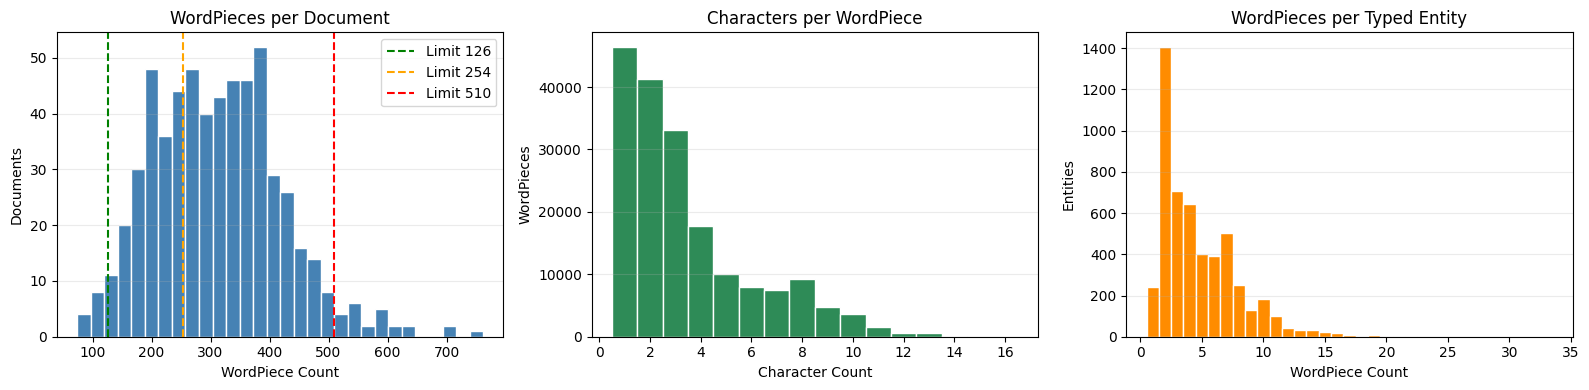

,Count,Percentage
Label,,
O,160047,86.722
B-SpecificDisease,2972,1.610
I-SpecificDisease,12461,6.752
B-DiseaseClass,769,0.417
I-DiseaseClass,2919,1.582
B-CompositeMention,115,0.062
I-CompositeMention,946,0.513
B-Modifier,1289,0.698
I-Modifier,3034,1.644


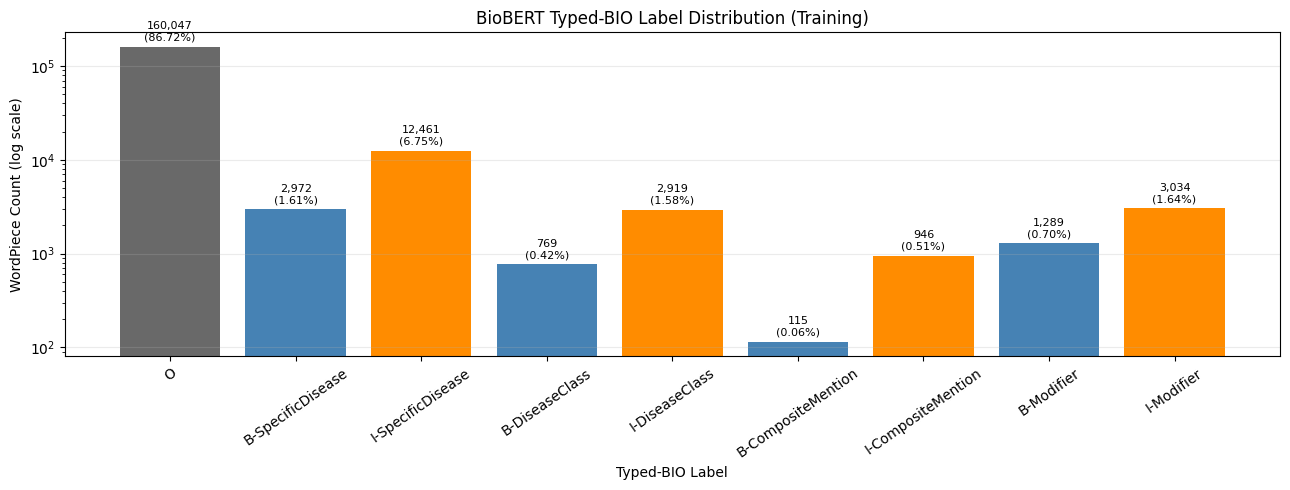

In [15]:
from collections import Counter

# Load all BioBERT-tokenized splits and validate the shared JSONL schema.
biobert_files = {
    "Training": "NCBI_training.jsonl",
    "Validation": "NCBI_validation.jsonl",
    "Testing": "NCBI_testing.jsonl",
}
biobert_records_by_split = {}
required_tokenized_fields = {
    "record_id",
    "pmid",
    "model",
    "tokenizer",
    "text",
    "entities",
    "tokens",
    "input_ids",
    "attention_mask",
    "offset_mapping",
    "bio_tags",
}

for split, file_name in biobert_files.items():
    file_path = biobert_output_dir / file_name
    with file_path.open(encoding="utf-8") as source:
        records = [
            json.loads(line) for line in source if line.strip()
        ]

    for record in records:
        missing_fields = required_tokenized_fields - set(record)
        if missing_fields:
            raise ValueError(
                f"Missing fields {sorted(missing_fields)} in "
                f"{record.get('record_id', file_name)}"
            )
        sequence_lengths = {
            len(record["tokens"]),
            len(record["input_ids"]),
            len(record["attention_mask"]),
            len(record["offset_mapping"]),
        }
        if len(sequence_lengths) != 1:
            raise ValueError(
                f"Token sequence mismatch in {record['record_id']}"
            )

        if split == "Training":
            if len(record["bio_tags"]) != len(record["tokens"]):
                raise ValueError(
                    f"BIO alignment mismatch in {record['record_id']}"
                )
        elif record["entities"] or record["bio_tags"]:
            raise ValueError(
                f"Gold labels are not masked in {record['record_id']}"
            )

    biobert_records_by_split[split] = records

# Preserve the original analysis scope: descriptive statistics use Training.
biobert_records = biobert_records_by_split["Training"]

# Summarise tokenization volume for every split without using masked gold.
split_token_rows = []
for split, records in biobert_records_by_split.items():
    split_token_counts = pd.Series([
        len(record["tokens"]) for record in records
    ])
    split_token_rows.append({
        "Split": split,
        "Documents": len(records),
        "Total WordPieces": int(split_token_counts.sum()),
        "Mean WordPieces": split_token_counts.mean(),
        "Median WordPieces": split_token_counts.median(),
        "95th Percentile": split_token_counts.quantile(0.95),
        "Maximum WordPieces": int(split_token_counts.max()),
        "Documents > 510": int((split_token_counts > 510).sum()),
    })
split_token_summary = pd.DataFrame(split_token_rows).set_index("Split")
display(split_token_summary.round(2))

document_token_counts = [
    len(record["tokens"]) for record in biobert_records
]
token_character_lengths = [
    token_end - token_start
    for record in biobert_records
    for token_start, token_end in record["offset_mapping"]
]

entity_wordpiece_counts = []
boundary_aligned_entities = 0

for record in biobert_records:
    offsets = record["offset_mapping"]
    token_starts = {token_start for token_start, _ in offsets}
    token_ends = {token_end for _, token_end in offsets}

    for entity in record["entities"]:
        wordpiece_count = sum(
            token_start < entity["end"]
            and token_end > entity["start"]
            for token_start, token_end in offsets
        )
        entity_wordpiece_counts.append(wordpiece_count)

        is_boundary_aligned = (
            entity["start"] in token_starts
            and entity["end"] in token_ends
        )
        boundary_aligned_entities += int(is_boundary_aligned)


def describe_values(name, values):
    values = pd.Series(values)
    return {
        "Measurement": name,
        "Count": len(values),
        "Mean": values.mean(),
        "Median": values.median(),
        "Minimum": values.min(),
        "95th Percentile": values.quantile(0.95),
        "Maximum": values.max(),
    }


token_statistics = pd.DataFrame([
    describe_values("WordPieces per document", document_token_counts),
    describe_values("Characters per WordPiece", token_character_lengths),
    describe_values("WordPieces per entity", entity_wordpiece_counts),
]).set_index("Measurement")
display(token_statistics.round(2))

# Reserve two positions for [CLS] and [SEP].
capacity_rows = []
for model_max_length in (128, 256, 512):
    content_limit = model_max_length - 2
    exceeding_count = sum(
        count > content_limit for count in document_token_counts
    )
    capacity_rows.append({
        "Model Max Length": model_max_length,
        "Content WordPiece Limit": content_limit,
        "Documents Exceeding Limit": exceeding_count,
        "Documents Exceeding Limit (%)": (
            exceeding_count / len(document_token_counts) * 100
        ),
    })

capacity_summary = pd.DataFrame(capacity_rows).set_index(
    "Model Max Length"
)
display(capacity_summary.round(2))

total_entities = len(entity_wordpiece_counts)
single_wordpiece_entities = sum(
    count == 1 for count in entity_wordpiece_counts
)
entity_alignment_summary = pd.DataFrame({
    "Metric": [
        "Single-WordPiece entities",
        "Multi-WordPiece entities",
        "Boundary-aligned entities",
        "Boundary-unaligned entities",
    ],
    "Count": [
        single_wordpiece_entities,
        total_entities - single_wordpiece_entities,
        boundary_aligned_entities,
        total_entities - boundary_aligned_entities,
    ],
}).set_index("Metric")
entity_alignment_summary["Percentage"] = (
    entity_alignment_summary["Count"] / total_entities * 100
)
display(entity_alignment_summary.round(2))

# Plot document, token, and entity tokenization distributions.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(
    document_token_counts,
    bins=30,
    color="steelblue",
    edgecolor="white",
)
for limit, color in zip((126, 254, 510), ("green", "orange", "red")):
    axes[0].axvline(
        limit,
        color=color,
        linestyle="--",
        label=f"Limit {limit}",
    )
axes[0].set_title("WordPieces per Document")
axes[0].set_xlabel("WordPiece Count")
axes[0].set_ylabel("Documents")
axes[0].legend()

token_length_bins = np.arange(
    0.5, max(token_character_lengths) + 1.5, 1
)
axes[1].hist(
    token_character_lengths,
    bins=token_length_bins,
    color="seagreen",
    edgecolor="white",
)
axes[1].set_title("Characters per WordPiece")
axes[1].set_xlabel("Character Count")
axes[1].set_ylabel("WordPieces")

entity_piece_bins = np.arange(
    0.5, max(entity_wordpiece_counts) + 1.5, 1
)
axes[2].hist(
    entity_wordpiece_counts,
    bins=entity_piece_bins,
    color="darkorange",
    edgecolor="white",
)
axes[2].set_title("WordPieces per Typed Entity")
axes[2].set_xlabel("WordPiece Count")
axes[2].set_ylabel("Entities")

for axis in axes:
    axis.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# Analyse the 4 * 2 + 1 typed-BIO labels in the training split only.
training_label_counts = Counter(
    tag
    for record in biobert_records
    for tag in record["bio_tags"]
)
unknown_labels = set(training_label_counts) - set(BIO_LABELS)
if unknown_labels:
    raise ValueError(
        f"Unknown BIO labels found: {sorted(unknown_labels)}"
    )

label_distribution = pd.DataFrame({
    "Label": BIO_LABELS,
    "Count": [training_label_counts[label] for label in BIO_LABELS],
})
label_distribution["Percentage"] = (
    label_distribution["Count"]
    / label_distribution["Count"].sum()
    * 100
)
display(label_distribution.set_index("Label").round(3))

label_colors = [
    "dimgray"
    if label == "O"
    else "steelblue"
    if label.startswith("B-")
    else "darkorange"
    for label in label_distribution["Label"]
]
fig, axis = plt.subplots(figsize=(13, 5))
bars = axis.bar(
    label_distribution["Label"],
    label_distribution["Count"],
    color=label_colors,
)
axis.set_yscale("log")
axis.bar_label(
    bars,
    labels=[
        f"{count:,}\n({percentage:.2f}%)"
        for count, percentage in zip(
            label_distribution["Count"],
            label_distribution["Percentage"],
        )
    ],
    padding=3,
    fontsize=8,
)
axis.set_title("BioBERT Typed-BIO Label Distribution (Training)")
axis.set_xlabel("Typed-BIO Label")
axis.set_ylabel("WordPiece Count (log scale)")
axis.tick_params(axis="x", rotation=35)
axis.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

#### 3.3.3 PubMedBERT

In [16]:
from transformers.models.bert.tokenization_bert import BertTokenizerFast

PUBMEDBERT_MODEL = (
    "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext"
)
dataset_files = (
    "NCBI_training.jsonl",
    "NCBI_validation.jsonl",
    "NCBI_testing.jsonl",
)
pubmedbert_output_dir = (
    project_dir / "Dataset" / "TokenizedData" / "PubMedBERT"
)
pubmedbert_output_dir.mkdir(parents=True, exist_ok=True)
pubmedbert_training_path = (
    pubmedbert_output_dir / "NCBI_training.jsonl"
)


def tokenize_pubmedbert_dataset(
    input_path,
    output_path,
    tokenizer,
    include_gold_labels,
):
    document_count = 0
    token_count = 0

    with input_path.open(encoding="utf-8") as source:
        with output_path.open("w", encoding="utf-8") as destination:
            for line in source:
                if not line.strip():
                    continue

                record = json.loads(line)
                encoded = tokenizer(
                    record["text"],
                    add_special_tokens=False,
                    truncation=False,
                    return_attention_mask=True,
                    return_offsets_mapping=True,
                )
                tokens = tokenizer.convert_ids_to_tokens(
                    encoded["input_ids"]
                )
                offsets = [
                    [start, end]
                    for start, end in encoded["offset_mapping"]
                ]

                has_invalid_offset = any(
                    not 0 <= token_start < token_end
                    <= len(record["text"])
                    for token_start, token_end in offsets
                )
                if has_invalid_offset:
                    raise ValueError(
                        f"Invalid token offset in {record['record_id']}"
                    )

                sequence_lengths = (
                    len(tokens),
                    len(encoded["input_ids"]),
                    len(encoded["attention_mask"]),
                    len(offsets),
                )
                bio_tags = None
                if include_gold_labels:
                    bio_tags = create_typed_bio_tags(
                        offsets,
                        record["entities"],
                        record["record_id"],
                    )
                    sequence_lengths += (len(bio_tags),)
                if len(set(sequence_lengths)) != 1:
                    raise ValueError(
                        f"Token alignment failed for {record['record_id']}"
                    )

                tokenized_record = {
                    "record_id": record["record_id"],
                    "pmid": record["pmid"],
                    "model": PUBMEDBERT_MODEL,
                    "tokenizer": PUBMEDBERT_MODEL,
                    "text": record["text"],
                    "entities": [],
                    "tokens": tokens,
                    "input_ids": encoded["input_ids"],
                    "attention_mask": encoded["attention_mask"],
                    "offset_mapping": offsets,
                    "bio_tags": [],
                }
                if include_gold_labels:
                    tokenized_record["entities"] = record["entities"]
                    tokenized_record["bio_tags"] = bio_tags
                destination.write(
                    json.dumps(tokenized_record, ensure_ascii=False)
                    + "\n"
                )
                document_count += 1
                token_count += len(tokens)

    return document_count, token_count


# PubMedBERT provides its own biomedical WordPiece vocabulary.
pubmedbert_tokenizer = BertTokenizerFast.from_pretrained(
    PUBMEDBERT_MODEL
)
if not pubmedbert_tokenizer.is_fast:
    raise RuntimeError(
        "PubMedBERT fast tokenizer is required for offset mapping."
    )

for file_name in dataset_files:
    input_path = processed_data_dir / file_name
    output_path = pubmedbert_output_dir / file_name
    include_gold_labels = file_name == "NCBI_training.jsonl"
    document_count, token_count = tokenize_pubmedbert_dataset(
        input_path,
        output_path,
        pubmedbert_tokenizer,
        include_gold_labels,
    )
    print(
        f"Saved {document_count} PubMedBERT-tokenized documents to: "
        f"{output_path}"
    )
    print(f"Total WordPiece tokens: {token_count}")
    print(
        "Gold entities and BIO tags: "
        + ("included" if include_gold_labels else "masked")
    )

Saved 593 PubMedBERT-tokenized documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\TokenizedData\PubMedBERT\NCBI_training.jsonl
Total WordPiece tokens: 147944
Gold entities and BIO tags: included
Saved 100 PubMedBERT-tokenized documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\TokenizedData\PubMedBERT\NCBI_validation.jsonl
Total WordPiece tokens: 25638
Gold entities and BIO tags: masked
Saved 100 PubMedBERT-tokenized documents to: C:\Users\33465\Desktop\UNSW课程\2026T3\Comp9444\GroupProject\MedNLP_Research\Dataset\TokenizedData\PubMedBERT\NCBI_testing.jsonl
Total WordPiece tokens: 26560
Gold entities and BIO tags: masked


#### 3.3.4 PubMedBERT 分词结果分析

,Documents,Total WordPieces,Mean WordPieces,Median WordPieces,95th Percentile,Maximum WordPieces,Documents > 510
Split,,,,,,,
Training,593,147944,249.48,248.0,393.6,676,6
Validation,100,25638,256.38,249.5,386.6,433,0
Testing,100,26560,265.60,257.5,401.1,557,1


,Count,Mean,Median,Minimum,95th Percentile,Maximum
Measurement,,,,,,
WordPieces per document,593,249.48,248.0,58,393.6,676
Characters per WordPiece,147944,4.30,3.0,1,10.0,21
WordPieces per entity,5145,3.00,2.0,1,7.0,22


,Content WordPiece Limit,Documents Exceeding Limit,Documents Exceeding Limit (%)
Model Max Length,,,
128,126,556,93.76
256,254,282,47.55
512,510,6,1.01


,Count,Percentage
Metric,,
Single-WordPiece entities,1308,25.42
Multi-WordPiece entities,3837,74.58
Boundary-aligned entities,5145,100.00
Boundary-unaligned entities,0,0.00


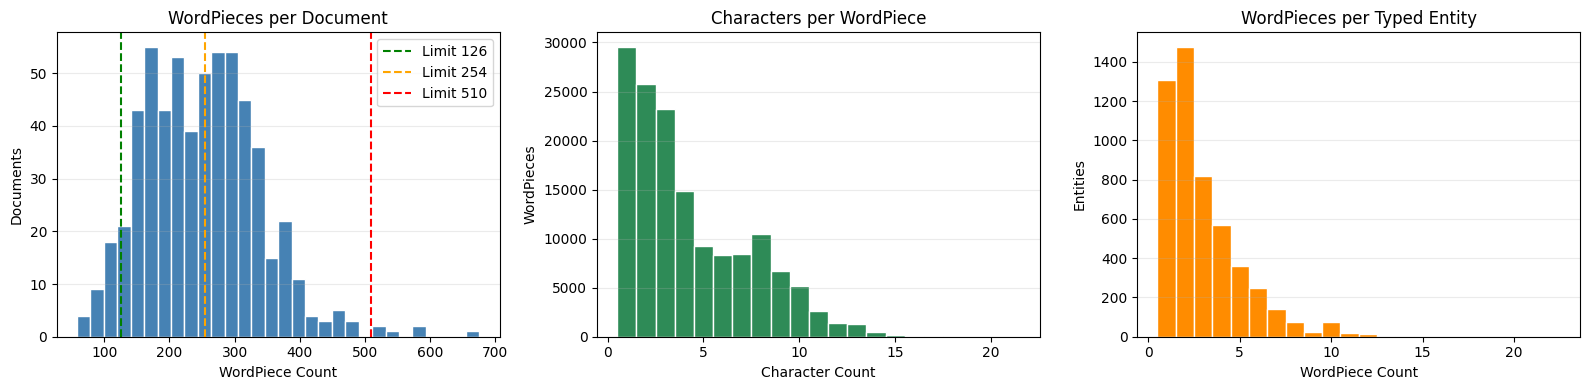

,Count,Percentage
Label,,
O,132484,89.550
B-SpecificDisease,2972,2.009
I-SpecificDisease,6834,4.619
B-DiseaseClass,769,0.520
I-DiseaseClass,1390,0.940
B-CompositeMention,115,0.078
I-CompositeMention,588,0.397
B-Modifier,1289,0.871
I-Modifier,1503,1.016


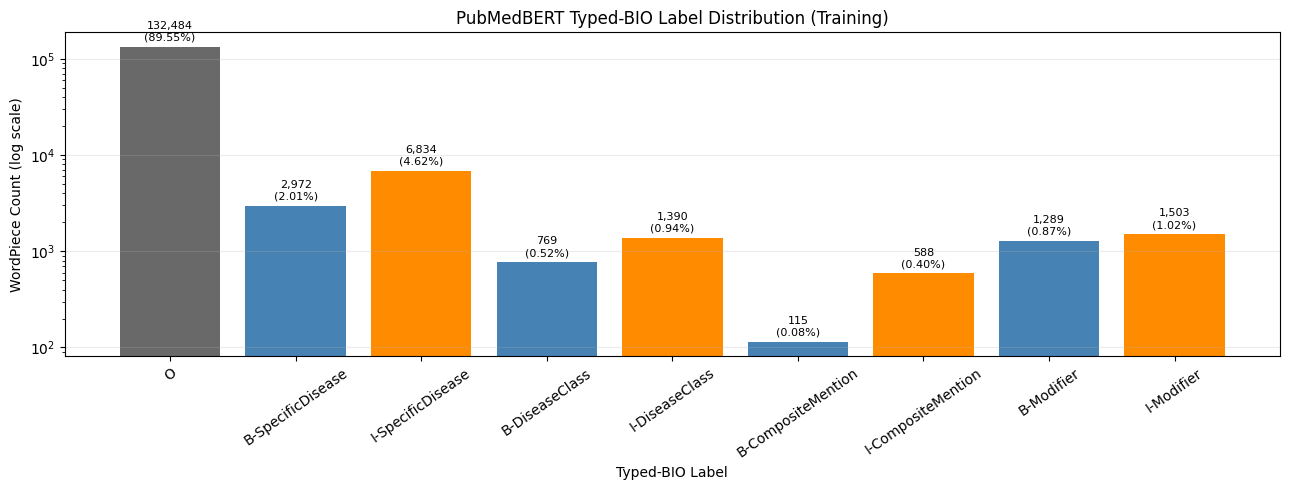

In [17]:
from collections import Counter

# Load all PubMedBERT-tokenized splits and validate the shared JSONL schema.
pubmedbert_files = {
    "Training": "NCBI_training.jsonl",
    "Validation": "NCBI_validation.jsonl",
    "Testing": "NCBI_testing.jsonl",
}
pubmedbert_records_by_split = {}
pubmedbert_required_fields = {
    "record_id",
    "pmid",
    "model",
    "tokenizer",
    "text",
    "entities",
    "tokens",
    "input_ids",
    "attention_mask",
    "offset_mapping",
    "bio_tags",
}

for split, file_name in pubmedbert_files.items():
    file_path = pubmedbert_output_dir / file_name
    with file_path.open(encoding="utf-8") as source:
        records = [
            json.loads(line) for line in source if line.strip()
        ]

    for record in records:
        missing_fields = pubmedbert_required_fields - set(record)
        if missing_fields:
            raise ValueError(
                f"Missing fields {sorted(missing_fields)} in "
                f"{record.get('record_id', file_name)}"
            )
        sequence_lengths = {
            len(record["tokens"]),
            len(record["input_ids"]),
            len(record["attention_mask"]),
            len(record["offset_mapping"]),
        }
        if len(sequence_lengths) != 1:
            raise ValueError(
                f"Token sequence mismatch in {record['record_id']}"
            )

        if split == "Training":
            if len(record["bio_tags"]) != len(record["tokens"]):
                raise ValueError(
                    f"BIO alignment mismatch in {record['record_id']}"
                )
        elif record["entities"] or record["bio_tags"]:
            raise ValueError(
                f"Gold labels are not masked in {record['record_id']}"
            )

    pubmedbert_records_by_split[split] = records

# Preserve the original analysis scope: detailed statistics use Training.
pubmedbert_records = pubmedbert_records_by_split["Training"]

# Summarise tokenization volume for every split without using masked gold.
pubmedbert_split_token_rows = []
for split, records in pubmedbert_records_by_split.items():
    split_token_counts = pd.Series([
        len(record["tokens"]) for record in records
    ])
    pubmedbert_split_token_rows.append({
        "Split": split,
        "Documents": len(records),
        "Total WordPieces": int(split_token_counts.sum()),
        "Mean WordPieces": split_token_counts.mean(),
        "Median WordPieces": split_token_counts.median(),
        "95th Percentile": split_token_counts.quantile(0.95),
        "Maximum WordPieces": int(split_token_counts.max()),
        "Documents > 510": int((split_token_counts > 510).sum()),
    })
pubmedbert_split_token_summary = pd.DataFrame(
    pubmedbert_split_token_rows
).set_index("Split")
display(pubmedbert_split_token_summary.round(2))

pubmedbert_document_token_counts = [
    len(record["tokens"]) for record in pubmedbert_records
]
pubmedbert_token_character_lengths = [
    token_end - token_start
    for record in pubmedbert_records
    for token_start, token_end in record["offset_mapping"]
]
pubmedbert_entity_wordpiece_counts = []
pubmedbert_boundary_aligned_entities = 0

for record in pubmedbert_records:
    offsets = record["offset_mapping"]
    token_starts = {token_start for token_start, _ in offsets}
    token_ends = {token_end for _, token_end in offsets}

    for entity in record["entities"]:
        wordpiece_count = sum(
            token_start < entity["end"]
            and token_end > entity["start"]
            for token_start, token_end in offsets
        )
        pubmedbert_entity_wordpiece_counts.append(wordpiece_count)

        is_boundary_aligned = (
            entity["start"] in token_starts
            and entity["end"] in token_ends
        )
        pubmedbert_boundary_aligned_entities += int(
            is_boundary_aligned
        )


def describe_pubmedbert_values(name, values):
    values = pd.Series(values)
    return {
        "Measurement": name,
        "Count": len(values),
        "Mean": values.mean(),
        "Median": values.median(),
        "Minimum": values.min(),
        "95th Percentile": values.quantile(0.95),
        "Maximum": values.max(),
    }


pubmedbert_token_statistics = pd.DataFrame([
    describe_pubmedbert_values(
        "WordPieces per document",
        pubmedbert_document_token_counts,
    ),
    describe_pubmedbert_values(
        "Characters per WordPiece",
        pubmedbert_token_character_lengths,
    ),
    describe_pubmedbert_values(
        "WordPieces per entity",
        pubmedbert_entity_wordpiece_counts,
    ),
]).set_index("Measurement")
display(pubmedbert_token_statistics.round(2))

pubmedbert_capacity_rows = []
for model_max_length in (128, 256, 512):
    content_limit = model_max_length - 2
    exceeding_count = sum(
        count > content_limit
        for count in pubmedbert_document_token_counts
    )
    pubmedbert_capacity_rows.append({
        "Model Max Length": model_max_length,
        "Content WordPiece Limit": content_limit,
        "Documents Exceeding Limit": exceeding_count,
        "Documents Exceeding Limit (%)": (
            exceeding_count
            / len(pubmedbert_document_token_counts)
            * 100
        ),
    })

pubmedbert_capacity_summary = pd.DataFrame(
    pubmedbert_capacity_rows
).set_index("Model Max Length")
display(pubmedbert_capacity_summary.round(2))

pubmedbert_total_entities = len(
    pubmedbert_entity_wordpiece_counts
)
pubmedbert_single_wordpiece_entities = sum(
    count == 1 for count in pubmedbert_entity_wordpiece_counts
)
pubmedbert_entity_alignment_summary = pd.DataFrame({
    "Metric": [
        "Single-WordPiece entities",
        "Multi-WordPiece entities",
        "Boundary-aligned entities",
        "Boundary-unaligned entities",
    ],
    "Count": [
        pubmedbert_single_wordpiece_entities,
        pubmedbert_total_entities
        - pubmedbert_single_wordpiece_entities,
        pubmedbert_boundary_aligned_entities,
        pubmedbert_total_entities
        - pubmedbert_boundary_aligned_entities,
    ],
}).set_index("Metric")
pubmedbert_entity_alignment_summary["Percentage"] = (
    pubmedbert_entity_alignment_summary["Count"]
    / pubmedbert_total_entities
    * 100
)
display(pubmedbert_entity_alignment_summary.round(2))

# Plot the PubMedBERT tokenization distributions.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(
    pubmedbert_document_token_counts,
    bins=30,
    color="steelblue",
    edgecolor="white",
)
for limit, color in zip((126, 254, 510), ("green", "orange", "red")):
    axes[0].axvline(
        limit,
        color=color,
        linestyle="--",
        label=f"Limit {limit}",
    )
axes[0].set_title("WordPieces per Document")
axes[0].set_xlabel("WordPiece Count")
axes[0].set_ylabel("Documents")
axes[0].legend()

pubmedbert_token_length_bins = np.arange(
    0.5, max(pubmedbert_token_character_lengths) + 1.5, 1
)
axes[1].hist(
    pubmedbert_token_character_lengths,
    bins=pubmedbert_token_length_bins,
    color="seagreen",
    edgecolor="white",
)
axes[1].set_title("Characters per WordPiece")
axes[1].set_xlabel("Character Count")
axes[1].set_ylabel("WordPieces")

pubmedbert_entity_piece_bins = np.arange(
    0.5, max(pubmedbert_entity_wordpiece_counts) + 1.5, 1
)
axes[2].hist(
    pubmedbert_entity_wordpiece_counts,
    bins=pubmedbert_entity_piece_bins,
    color="darkorange",
    edgecolor="white",
)
axes[2].set_title("WordPieces per Typed Entity")
axes[2].set_xlabel("WordPiece Count")
axes[2].set_ylabel("Entities")

for axis in axes:
    axis.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# Analyse the 4 * 2 + 1 typed-BIO labels in the training split only.
pubmedbert_training_label_counts = Counter(
    tag
    for record in pubmedbert_records
    for tag in record["bio_tags"]
)
pubmedbert_unknown_labels = (
    set(pubmedbert_training_label_counts) - set(BIO_LABELS)
)
if pubmedbert_unknown_labels:
    raise ValueError(
        "Unknown BIO labels found: "
        f"{sorted(pubmedbert_unknown_labels)}"
    )

pubmedbert_label_distribution = pd.DataFrame({
    "Label": BIO_LABELS,
    "Count": [
        pubmedbert_training_label_counts[label]
        for label in BIO_LABELS
    ],
})
pubmedbert_label_distribution["Percentage"] = (
    pubmedbert_label_distribution["Count"]
    / pubmedbert_label_distribution["Count"].sum()
    * 100
)
display(
    pubmedbert_label_distribution.set_index("Label").round(3)
)

pubmedbert_label_colors = [
    "dimgray"
    if label == "O"
    else "steelblue"
    if label.startswith("B-")
    else "darkorange"
    for label in pubmedbert_label_distribution["Label"]
]
fig, axis = plt.subplots(figsize=(13, 5))
bars = axis.bar(
    pubmedbert_label_distribution["Label"],
    pubmedbert_label_distribution["Count"],
    color=pubmedbert_label_colors,
)
axis.set_yscale("log")
axis.bar_label(
    bars,
    labels=[
        f"{count:,}\n({percentage:.2f}%)"
        for count, percentage in zip(
            pubmedbert_label_distribution["Count"],
            pubmedbert_label_distribution["Percentage"],
        )
    ],
    padding=3,
    fontsize=8,
)
axis.set_title("PubMedBERT Typed-BIO Label Distribution (Training)")
axis.set_xlabel("Typed-BIO Label")
axis.set_ylabel("WordPiece Count (log scale)")
axis.tick_params(axis="x", rotation=35)
axis.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## **_4. Standardized Testing_**

In [ ]:
from collections import Counter
import json
from pathlib import Path

import pandas as pd


def load_jsonl_records(file_path):
    records = []
    with Path(file_path).open(encoding="utf-8") as source:
        for line_number, line in enumerate(source, start=1):
            if not line.strip():
                continue
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as error:
                raise ValueError(
                    f"Invalid JSON on line {line_number}: {file_path}"
                ) from error
    return records


def index_records(records, source_name):
    indexed = {}
    for record in records:
        record_id = record.get("record_id")
        if not isinstance(record_id, str) or not record_id:
            raise ValueError(f"Missing record_id in {source_name}")
        if record_id in indexed:
            raise ValueError(
                f"Duplicate record_id {record_id} in {source_name}"
            )
        indexed[record_id] = record
    return indexed


def validate_span(entity, record_id, text_length):
    if set(entity) != {"start", "end"}:
        raise ValueError(
            f"Entity in {record_id} must contain only start and end"
        )
    start, end = entity["start"], entity["end"]
    valid_types = (
        isinstance(start, int)
        and not isinstance(start, bool)
        and isinstance(end, int)
        and not isinstance(end, bool)
    )
    if not valid_types or not 0 <= start < end <= text_length:
        raise ValueError(
            f"Invalid span [{start}, {end}) in {record_id}"
        )
    return start, end


def validate_prediction(prediction, gold_record):
    required_fields = {"record_id", "pmid", "entities"}
    if set(prediction) != required_fields:
        raise ValueError(
            f"Prediction {prediction.get('record_id')} must contain only "
            "record_id, pmid, and entities"
        )
    record_id = prediction["record_id"]
    if prediction["pmid"] != gold_record["pmid"]:
        raise ValueError(f"PMID mismatch for {record_id}")
    if not isinstance(prediction["entities"], list):
        raise ValueError(f"entities must be a list in {record_id}")

    text_length = len(gold_record["text"])
    spans = [
        validate_span(entity, record_id, text_length)
        for entity in prediction["entities"]
    ]
    if spans != sorted(spans):
        raise ValueError(f"Entities are not sorted in {record_id}")
    if len(spans) != len(set(spans)):
        raise ValueError(f"Duplicate entity spans in {record_id}")
    return spans


def calculate_prf(tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall
        else 0.0
    )
    return {
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }


def set_counts(gold_values, predicted_values):
    return (
        len(gold_values & predicted_values),
        len(predicted_values - gold_values),
        len(gold_values - predicted_values),
    )


def boundary_counts(gold_values, predicted_values):
    gold_counter = Counter(gold_values)
    predicted_counter = Counter(predicted_values)
    return (
        sum((gold_counter & predicted_counter).values()),
        sum((predicted_counter - gold_counter).values()),
        sum((gold_counter - predicted_counter).values()),
    )


def spans_to_characters(spans):
    characters = set()
    for start, end in spans:
        characters.update(range(start, end))
    return characters


def add_counts(total, current):
    for index, value in enumerate(current):
        total[index] += value


def evaluate_standardized_records(gold_records, prediction_records):
    gold_by_id = index_records(gold_records, "gold records")
    pred_by_id = index_records(prediction_records, "predictions")
    missing = sorted(set(gold_by_id) - set(pred_by_id))
    extra = sorted(set(pred_by_id) - set(gold_by_id))
    if missing or extra:
        raise ValueError(
            f"Record mismatch: missing={missing}, extra={extra}"
        )

    exact_total = [0, 0, 0]
    start_total = [0, 0, 0]
    end_total = [0, 0, 0]
    character_total = [0, 0, 0]
    gold_entity_count = 0
    predicted_entity_count = 0

    for record_id, gold_record in gold_by_id.items():
        text_length = len(gold_record["text"])
        gold_spans = [
            validate_span(entity, record_id, text_length)
            for entity in gold_record["entities"]
        ]
        predicted_spans = validate_prediction(
            pred_by_id[record_id], gold_record
        )
        gold_entity_count += len(gold_spans)
        predicted_entity_count += len(predicted_spans)

        add_counts(
            exact_total, set_counts(set(gold_spans), set(predicted_spans))
        )
        add_counts(
            start_total,
            boundary_counts(
                [start for start, _ in gold_spans],
                [start for start, _ in predicted_spans],
            ),
        )
        add_counts(
            end_total,
            boundary_counts(
                [end for _, end in gold_spans],
                [end for _, end in predicted_spans],
            ),
        )
        add_counts(
            character_total,
            set_counts(
                spans_to_characters(gold_spans),
                spans_to_characters(predicted_spans),
            ),
        )

    return {
        "averaging": "micro",
        "document_count": len(gold_by_id),
        "gold_entity_count": gold_entity_count,
        "predicted_entity_count": predicted_entity_count,
        "exact_span": calculate_prf(*exact_total),
        "start_boundary": calculate_prf(*start_total),
        "end_boundary": calculate_prf(*end_total),
        "character_overlap": calculate_prf(*character_total),
    }


def evaluate_model_predictions(prediction_records, split):
    # Select the gold file while keeping one shared public evaluation entry point.
    if not isinstance(prediction_records, list):
        raise TypeError("prediction_records must be a list of dictionaries")
    if not all(isinstance(record, dict) for record in prediction_records):
        raise TypeError("Every prediction record must be a dictionary")

    if not isinstance(split, str):
        raise TypeError("split must be a string: 'validation' or 'test'")

    split_name = split.strip().lower()
    gold_file_names = {
        "validation": "NCBI_validation.jsonl",
        "test": "NCBI_testing.jsonl",
    }
    if split_name not in gold_file_names:
        raise ValueError("split must be 'validation' or 'test'")

    current_directory = Path.cwd().resolve()
    project_root = next(
        (
            path
            for path in (current_directory, *current_directory.parents)
            if (path / "Dataset" / "ProcessedData").is_dir()
        ),
        None,
    )
    if project_root is None:
        raise FileNotFoundError(
            "Could not locate Dataset/ProcessedData from the current directory"
        )

    gold_path = (
        project_root
        / "Dataset"
        / "ProcessedData"
        / gold_file_names[split_name]
    )
    return evaluate_standardized_records(
        load_jsonl_records(gold_path),
        prediction_records,
    )


def metrics_to_table(metrics):
    metric_names = {
        "exact_span": "Exact span",
        "start_boundary": "Start boundary",
        "end_boundary": "End boundary",
        "character_overlap": "Character overlap",
    }
    rows = []
    for metric_key, metric_name in metric_names.items():
        values = metrics[metric_key]
        rows.append({
            "Metric": metric_name,
            "TP": values["true_positives"],
            "FP": values["false_positives"],
            "FN": values["false_negatives"],
            "Precision": values["precision"],
            "Recall": values["recall"],
            "F1": values["f1"],
        })
    return pd.DataFrame(rows).set_index("Metric")


def save_metrics(metrics, output_path):
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    with output_path.open("w", encoding="utf-8") as destination:
        json.dump(metrics, destination, indent=2, ensure_ascii=False)


# Example usage after the model has produced prediction_records in memory:
# metrics = evaluate_model_predictions(prediction_records, "test")
# display(metrics_to_table(metrics).round(4))
# save_metrics(
#     metrics,
#     project_dir / "results" / "B1_test_metrics.json",
# )


print("Standardized evaluation functions are ready.")